# Tests de validation MSUC

Ce notebook entraine la politique SDDP sur une instance puis la simule. On choisit l'instance,
l'horizon, le nombre de scenarios, la formulation (3-bin ou intervalle) et les reglages de `train`
(nombre d'iterations, ecart d'optimalite du MIP racine), puis on regarde la trajectoire de la borne
inferieure, le cout de la politique simulee et la repartition du temps de calcul.

Les verifications rigoureuses (borne <= optimum exact <= politique, equivalence des formulations
3-bin et intervalle, Prop. 3) sont dans `examples/toy_convergence.jl` et `examples/compare_formulations.jl`.

A executer depuis la racine du depot (le kernel Julia active automatiquement ce projet).

## 1. Installation des dependances (une seule fois)

Installe les paquets listes dans `Project.toml` (JuMP, Gurobi.jl, CSV, DataFrames, NCDatasets, ...). 
Necessite une licence Gurobi valide sur la machine.

In [1]:
import Pkg
Pkg.activate(@__DIR__)  # active ce projet, quel que soit le kernel Julia choisi
Pkg.instantiate()

  Activating project at `~/Documents/MSUC`


In [2]:
using MSUC, Gurobi, Printf, Random

GRB_ENV = Gurobi.Env()
optimizer = () -> Gurobi.Optimizer(GRB_ENV)

Set parameter Username
Set parameter LicenseID to value 2818369
Academic license - for non-commercial use only - expires 2027-05-05


#2 (generic function with 1 method)

In [3]:
INSTANCE    = "Data/T-Ramp/100_0_2_w.nc4"  # chemin vers le fichier .nc4
T           = 24                           # horizon (nombre de pas de temps)
S           = 5                            # nombre de scenarios (support de l'innovation ARMA)
SIGMA       = 1.0                          # amplitude de l'alea : multiplie l'ecart-type de l'innovation ARMA (0.0 = deterministe)
ITERATIONS  = 70                          # nombre d'iterations SDDP
MIP_GAP     = 1e-3                         # ecart d'optimalite du MIP racine : 1e-2 = 1 %, 1e-3 = 0.1 %, nothing = defaut du solveur (1e-4)
PASSES_PER_MIP = 15                         # passes avant/arriere (LP) par resolution du MIP racine : 1 = usuel, 5 ou 10 = plus de coupes entre deux MIP ; ITERATIONS compte alors des cycles
PRINT_LEVEL = 1                            # 0 = silencieux, 1 = log complet de MSUC.train

# :threebin  -> formulation 3-bin  (Sect. 2 de l'article, coupes (12))
# :extended  -> formulation intervalle (Sect. 3 de l'article, coupes (41))
METHOD = :extended

:extended

In [4]:
FORMULATIONS = Dict(
    :threebin => (MSUC.subproblem_builder_UC_def,     MSUC.SDDPFormulation,     "3-bin"),
    :extended => (MSUC.subproblem_builder_UC_extended, MSUC.ExtendedFormulation, "intervalle"),
)
builder, method, label = FORMULATIONS[METHOD]

instance = MSUC.parse_nc4(INSTANCE, optimizer, T; S = S, sigma = SIGMA)
@printf("instance %s : %d unites, %d intervalles, T = %d, S = %d, methode = %s\n",
        basename(INSTANCE), instance.N,
        sum(length(u.intervals) for u in instance.Thermalunits), T, S, label)

instance 100_0_2_w.nc4 : 100 unites, 20715 intervalles, T = 24, S = 5, methode = intervalle


In [5]:
model = MSUC.PolicyGraph(
    builder, instance, 1.0, MSUC.Graph(T + 1), method;   # force = 1 : l'amplitude de l'alea est donnee par SIGMA
    lower_bound = 0.0, optimizer = optimizer,
)

# Garde, sans toucher a l'algorithme, le planning x^k et les etats echantillonnes de chaque iteration
# (en formulation intervalle, avec l'etat par intervalle ytilde^k de la passe avant : diagnostics ci-dessous)
# (memes enregistrements que `train_job` de runSMS.jl)
record, record_pass, _, schedules, states = MSUC.make_recorder(model; interval_states = true)

Random.seed!(MSUC.SEED)   # meme graine que `train_job` (runSMS.jl) : les runs sont reproductibles
MSUC.train(model; iteration_limit = ITERATIONS, mip_gap = MIP_GAP,
            passes_per_mip = PASSES_PER_MIP, print_level = PRINT_LEVEL,
            forward_pass_callback = record_pass, post_iteration_callback = record)

-------------------------------------------------------------------
         MSUC.jl (c) Oscar Dowson and contributors, 2017-25
-------------------------------------------------------------------
problem
  nodes           : 25
  state variables : 102
  scenarios       : 5.96046e+16
  existing cuts   : false
subproblem structure
  VariableRef                             : [709, 28220]
  AffExpr in MOI.EqualTo{Float64}         : [3, 9928]
  AffExpr in MOI.GreaterThan{Float64}     : [1, 101]
  AffExpr in MOI.LessThan{Float64}        : [400, 9600]
  VariableRef in MOI.EqualTo{Float64}     : [501, 501]
  VariableRef in MOI.GreaterThan{Float64} : [102, 20815]
  VariableRef in MOI.LessThan{Float64}    : [100, 100]
  VariableRef in MOI.ZeroOne              : [7300, 7300]
numerical stability report
  matrix range     [1e-01, 1e+04]
  objective range  [1e+00, 4e+03]
  bounds range     [1e+02, 3e+02]
  rhs range        [1e+00, 1e+04]
---------------------------------------------------------------

innovation : 5 points de -4.87 % a 4.87 % (ecart-type 1.70 %, soit sigma = 1.00) ; 5^24 trajectoires possibles, 200 tirees, 1050 visitees par les passes avant


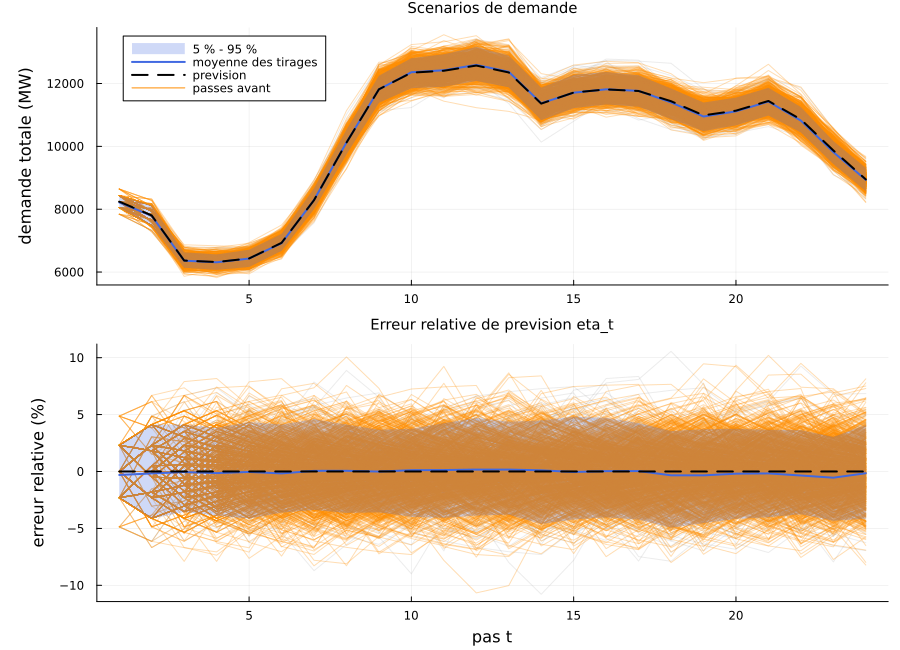

In [6]:
# Scenarios de demande. La demande du noeud b a l'etape t vaut Demandbus[b][t] * (1 + eta_t), ou
# eta_t = S_eta zeta_t est l'erreur relative de prevision (la meme sur tous les noeuds), zeta_t = Psi zeta_{t-1} + E xi_t,
# et l'innovation xi_t prend S valeurs : il y a S^T trajectoires possibles, dont on tire ici N_SCENARIOS au hasard.
using Plots, Statistics, Random, Printf

N_SCENARIOS = 200            # trajectoires tirees dans la loi du modele
AVEC_PASSES_AVANT = true     # superposer les trajectoires visitees par les passes avant de l'entrainement

arma = instance.arma
prevision = [sum(instance.Demandbus[b][t] for b in eachindex(instance.Demandbus)) for t in 1:T]   # demande totale prevue

# erreur relative eta_1, ..., eta_T d'une suite d'innovations xi_1, ..., xi_T
function erreur_relative(innovations)
    zeta = copy(arma.zeta0)
    eta = zeros(length(innovations))
    for (t, xi) in enumerate(innovations)
        zeta = arma.Psi * zeta + arma.E * xi
        eta[t] = sum(arma.S_eta[1, :] .* zeta)
    end
    return eta
end

let
    rng = MersenneTwister(MSUC.SEED)
    cumul = cumsum(arma.probability)
    tirer() = arma.support[min(searchsortedfirst(cumul, rand(rng)), length(cumul))]
    eta = reduce(hcat, [erreur_relative([tirer() for _ in 1:T]) for _ in 1:N_SCENARIOS])      # T x N_SCENARIOS

    # trajectoires visitees par les passes avant : zeta_t est l'etat a la sortie du noeud t + 1
    visite = Matrix{Float64}(undef, T, 0)
    if AVEC_PASSES_AVANT && isdefined(Main, :states)
        trajectoires = [vec(arma.S_eta[1:1, :] * reduce(hcat, p.sampled_states_zeta)[:, 2:end]) for k in eachindex(states) for p in states[k]]
        visite = reduce(hcat, trajectoires)
    end

    # Les scenarios viennent de l'instance telle qu'elle a ete construite (cellule de l'instance) : si SIGMA ou S ont
    # change depuis, il faut relancer cette cellule (puis l'entrainement) pour que le trace les prenne en compte.
    xs = [x[1] for x in arma.support]
    S_instance = length(xs)
    ecart_type = sqrt(sum(arma.probability .* xs .^ 2))
    sigma_instance = ecart_type / sqrt(MSUC.ARMA_INNOVATION_VARIANCE)
    @printf("innovation : %d points de %.2f %% a %.2f %% (ecart-type %.2f %%, soit sigma = %.2f) ; %d^%d trajectoires possibles, %d tirees",
            S_instance, 100 * minimum(xs), 100 * maximum(xs), 100 * ecart_type, sigma_instance, S_instance, T, N_SCENARIOS)
    size(visite, 2) > 0 && @printf(", %d visitees par les passes avant", size(visite, 2))
    println()
    S_instance == 1 && println("S = 1 : l'innovation est nulle (un seul point, 0), sigma n'a aucun effet")
    if S_instance != S || (S_instance > 1 && !isapprox(sigma_instance, SIGMA; atol = 1e-6))
        @warn "l'instance a ete construite avec S = $S_instance et sigma = $(round(sigma_instance; digits = 3)), alors que S = $S et SIGMA = $SIGMA : relancer la cellule de l'instance (et celle de l'entrainement)"
    end

    function panneau(valeurs, nominal, visitees; ylabel, titre)
        bas = [quantile(view(valeurs, t, :), 0.05) for t in 1:T]
        haut = [quantile(view(valeurs, t, :), 0.95) for t in 1:T]
        p = plot(1:T, valeurs; color = :gray, alpha = 0.15, label = "", ylabel = ylabel, title = titre, titlefontsize = 10)
        size(visitees, 2) > 0 && plot!(p, 1:T, visitees; color = :darkorange, alpha = 0.3, label = "")
        plot!(p, 1:T, bas; fillrange = haut, fillalpha = 0.25, color = :royalblue, linewidth = 0, label = "5 % - 95 %")
        plot!(p, 1:T, vec(mean(valeurs; dims = 2)); color = :royalblue, linewidth = 2, label = "moyenne des tirages")
        plot!(p, 1:T, nominal; color = :black, linewidth = 2, linestyle = :dash, label = "prevision")
        size(visitees, 2) > 0 && plot!(p, [NaN], [NaN]; color = :darkorange, label = "passes avant")
        return p
    end
    p1 = panneau(prevision .* (1 .+ eta), prevision, prevision .* (1 .+ visite); ylabel = "demande totale (MW)", titre = "Scenarios de demande")
    p2 = panneau(100 .* eta, zeros(T), 100 .* visite; ylabel = "erreur relative (%)", titre = "Erreur relative de prevision eta_t")
    plot(p1, p2; layout = (2, 1), size = (900, 650), xlabel = ["" "pas t"], legend = [:topleft :none], left_margin = 6Plots.mm)
end

### Resultats : trajectoire de la borne et cout de la politique simulee

it   1   borne = 273264.46   incumbent = 273264.46
it   2   borne = 3064231.14   incumbent = 3066822.38
it   3   borne = 3269966.41   incumbent = 3272367.37
it   4   borne = 3536610.88   incumbent = 3539999.34
it   5   borne = 3710031.94   incumbent = 3713503.47
it   6   borne = 14986201.43   incumbent = 14987634.96
it   7   borne = 15003518.99   incumbent = 15016169.82
it   8   borne = 15024282.80   incumbent = 15027975.31
it   9   borne = 15051148.64   incumbent = 15064347.53
it  10   borne = 15058836.09   incumbent = 15071710.62
it  11   borne = 15059755.17   incumbent = 15068260.26
it  12   borne = 15075125.96   incumbent = 15075999.51
it  13   borne = 15076421.65   incumbent = 15079661.99
it  14   borne = 15081299.23   incumbent = 15082808.74
it  15   borne = 15083110.39   incumbent = 15094064.04
it  16   borne = 15088933.69   incumbent = 15096939.92
it  17   borne = 15097364.25   incumbent = 15105496.09
it  18   borne = 15099344.56   incumbent = 15111828.98
it  19   borne = 15103

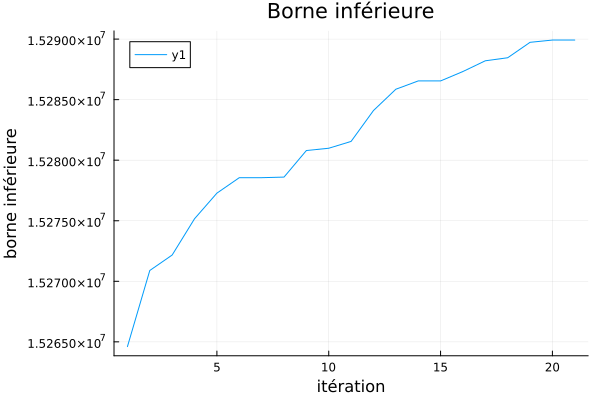

In [7]:
using Plots
log = model.most_recent_training_results.log
for l in log
    @printf("it %3d   borne = %.2f   incumbent = %.2f\n", l.iteration, l.bound, l.incumbent)
end
plot([l.bound for l in log if l.iteration >= 50], title = "Borne inférieure", xlabel = "itération", ylabel = "borne inférieure")

In [8]:
t_sim = @elapsed sim = MSUC.simulate(model; seed = MSUC.SEED)   # meme graine que `simulate_job` (runSMS.jl)
@printf("\ncout de la politique simulee = %.2f  (%d chemins, exhaustif = %s, %.1f s)\n",
        sim.cost, sim.npaths, sim.exhaustive, t_sim)
@printf("intervalle de confiance a 95 %% : [%.2f, %.2f]  (erreur standard %.2f)\n",
        sim.ci95[1], sim.ci95[2], sim.stderr)
@printf("borne finale = %.2f  ->  encadrement relatif = %.2e\n",
        log[end].bound, 100*(sim.cost - log[end].bound) / abs(log[end].bound))


cout de la politique simulee = 15362346.01  (1000 chemins, exhaustif = false, 49.2 s)
intervalle de confiance a 95 % : [15346149.33, 15378542.70]  (erreur standard 8263.61)
borne finale = 15289919.61  ->  encadrement relatif = 4.74e-01


### Diagnostic : intervalles choisis et etats echantillonnes

`schedules[k]` est le planning x^k choisi par le MIP racine a l'iteration k (en formulation intervalle,
ses intervalles sont dans `selected`) et `states[k][p]` la trajectoire de la passe avant p de l'iteration k :
`sampled_states_power[n]` et `sampled_states_zeta[n]` sont l'etat (production y, etat d'incertitude zeta) a la
sortie du noeud n ; le noeud 1 est l'etat initial et le noeud n l'etat a la fin du pas n-1.

La premiere cellule resume toutes les iterations (borne, incumbent, planning nouveau ou deja vu, variation des
etats echantillonnes) ; la seconde detaille une iteration en la comparant a la precedente ; la troisieme compare
y^k a y(gamma^k, ytilde^{k-1}) = somme, sur les intervalles choisis a l'iteration k, des points de linearisation
ytilde^{k-1}_{a,b,t} des coupes de l'iteration k-1 (construits a la passe avant de l'iteration k-1 : la production visitee si l'intervalle y etait
choisi, sinon la trajectoire de cout minimal sous les prix de cette passe) : c'est la production que ces coupes « attendent » pour le planning gamma^k. Un
ecart signifie que la coupe est evaluee en un autre point que celui ou elle a ete linearisee.

In [9]:
# Intervalles (unite, a, b) du planning x^k : l'unite est allumee aux pas a, ..., b-1 (b = T+1 : jusqu'a la fin
# de l'horizon ; a <= 0 : intervalle initial, l'unite est deja allumee au depart).
function intervalles(k)
    s, I = schedules[k], instance.intervals
    isempty(s.selected) || return [(I.unit[id], I.a[id], I.b[id]) for id in s.selected]
    # 3-bin : aucun intervalle n'est choisi, on relit les periodes de marche de u (colonne t+1 = pas t)
    out = Tuple{Int,Int,Int}[]
    for i in 1:instance.N
        t = 0
        while t <= T
            if s.u[i, t+1] > 0.5
                a = t
                while t < T && s.u[i, t+2] > 0.5
                    t += 1
                end
                push!(out, (i, a, t + 1))
            end
            t += 1
        end
    end
    return out
end

# Intervalles de l'iteration k, unite par unite
function par_unite(k)
    d = [Tuple{Int,Int}[] for _ in 1:instance.N]
    for (i, a, b) in intervalles(k)
        push!(d[i], (a, b))
    end
    return sort!.(d)
end

# Production y (unites x noeuds) le long de la passe avant p de l'iteration k
production(k, p = 1) = reduce(hcat, states[k][p].sampled_states_power)

# y(gamma^k, ytilde^{k-1}) = somme des gamma^k_{a,b} ytilde^{k-1}_{a,b,t} : la production que les coupes de
# l'iteration k-1 « attendent » quand le planning est gamma^k. ytilde^{k-1}_{a,b,t} est le point ou la coupe de
# l'iteration k-1 a ete linearisee pour l'intervalle [a, b], construit a la passe avant (regle des prix) : la
# production visitee y^{k-1}_t si l'intervalle etait choisi a l'iteration k-1, sinon la trajectoire de cout minimal
# sous les prix de cette passe. Seuls les intervalles actifs au pas t+1 portent un
# terme en y_t dans la coupe ; ailleurs la coupe ne depend pas de y_t et `attendu` vaut NaN. Colonne n = noeud n
# = pas n-1. `nouveau[i, n]` : l'intervalle n'etait pas choisi a l'iteration k-1.
function y_gamma(k)
    I = instance.intervals
    ytilde = states[k-1][end].sampled_states_interval    # derniere passe de l'iteration k-1 : la coupe la plus recente ; ytilde[n][id] = intervalle id a la sortie du noeud n
    deja = Set(schedules[k-1].selected)
    attendu = fill(NaN, instance.N, T + 1)
    nouveau = falses(instance.N, T + 1)
    for id in schedules[k].selected
        i, a, b = I.unit[id], I.a[id], I.b[id]
        for t in 0:(T-1)
            MSUC.is_on_interval(a, b, t + 1) || continue
            attendu[i, t+1] = ytilde[t+1][id]
            nouveau[i, t+1] = !(id in deja)
        end
    end
    return attendu, nouveau
end

# Plus grand ecart en valeur absolue, sans compter les NaN
max_abs(M) = maximum(abs, filter(!isnan, M); init = 0.0)

K = length(log)
@printf("%4s %12s %12s %10s %6s %9s %10s %10s  %s\n",
        "it", "borne", "incumbent", "ecart rel.", "#int.", "#changees", "max|dy|", "max|y-yg|", "planning")
for k in 1:K
    changees = k == 1 ? "-" : string(count(par_unite(k) .!= par_unite(k - 1)))   # unites dont les intervalles different de k-1
    dy = k == 1 ? "-" : @sprintf("%.3g", maximum(abs, production(k) .- production(k - 1)))
    dyg = METHOD == :extended && k >= 2 ? @sprintf("%.3g", max_abs(production(k) .- y_gamma(k)[1])) : "-"   # y^k - y(gamma^k, ytilde^{k-1})
    vu = findfirst(j -> schedules[j].x == schedules[k].x, 1:k-1)
    @printf("%4d %12.2f %12.2f %10.2e %6d %9s %10s %10s  %s\n",
            k, log[k].bound, log[k].incumbent, (log[k].incumbent - log[k].bound) / abs(log[k].incumbent),
            length(intervalles(k)), changees, dy, dyg, vu === nothing ? "nouveau" : "identique a l'iteration $vu")
end

  it        borne    incumbent ecart rel.  #int. #changees    max|dy|  max|y-yg|  planning
   1    273264.46    273264.46   2.98e-15     48         -          -          -  nouveau
   2   3064231.14   3066822.38   8.45e-04     75        63        328        252  nouveau
   3   3269966.41   3272367.37   7.34e-04     93        67        323        252  nouveau
   4   3536610.88   3539999.34   9.57e-04    124        84        311        252  nouveau
   5   3710031.94   3713503.47   9.35e-04     92        67        311        252  nouveau
   6  14986201.43  14987634.96   9.56e-05     92        52        304        252  nouveau
   7  15003518.99  15016169.82   8.42e-04     94        21        310        235  nouveau
   8  15024282.80  15027975.31   2.46e-04     91        20        304        252  nouveau
   9  15051148.64  15064347.53   8.76e-04     94        14        289        252  nouveau
  10  15058836.09  15071710.62   8.54e-04     93        17        324        235  nouveau
  11  150

Intervalles de l'iteration 69 ; * : unites qui different de l'iteration 68

   unite   1 : [-1, 25]
   unite   2 : [1, 25]
   unite   3 : [-6, 25]
   unite   4 : [-2, 4] [8, 25]
   unite   5 : [1, 4] [7, 25]
   unite   6 : [1, 25]
   unite   7 : [-2, 25]
   unite   8 : [-1, 25]
   unite   9 : [1, 25]
   unite  10 : [-4, 25]
   unite  11 : [6, 25]
   unite  12 : [1, 25]
   unite  13 : [-5, 25]
   unite  14 : [0, 25]
   unite  15 : [-1, 25]
   unite  16 : [-2, 25]
   unite  17 : [-2, 25]
   unite  18 : [1, 25]
   unite  19 : [-1, 25]
   unite  20 : [-3, 25]
   unite  21 : [1, 25]
   unite  22 : [-2, 25]
   unite  23 : [-4, 25]
   unite  24 : [6, 25]
   unite  25 : [1, 25]
   unite  26 : [6, 25]
   unite  27 : [-5, 25]
   unite  28 : [-1, 25]
   unite  29 : [1, 25]
   unite  30 : [1, 25]
   unite  31 : [1, 25]
 * unite  32 : [4, 25]  ->  [3, 25]
   unite  33 : [1, 25]
   unite  34 : [4, 25]
   unite  35 : [0, 25]
   unite  36 : [-5, 25]
   unite  37 : [6, 25]
   unite  38 : [-1, 25]
   un

2×25 Matrix{Float64}:
 0.0  0.0231  0.0413  0.0534  0.0385  …  -0.0278  -0.0213  -0.0143  0.0135
 0.0  0.0231  0.0231  0.0231  0.0        -0.0231   0.0      0.0     0.0231


Unites dont la production y differe d'au moins 1e-6 de celle de l'iteration 68 :
   unite   9 : ecart max   41.056 au noeud  4  (y = 93.561 contre 52.505)
   unite  18 : ecart max   26.271 au noeud  4  (y = 97.275 contre 71.004)
   unite  19 : ecart max   37.643 au noeud  4  (y = 121.000 contre 83.357)
   unite  21 : ecart max   37.823 au noeud  4  (y = 107.856 contre 70.034)
   unite  29 : ecart max   17.563 au noeud  4  (y = 79.445 contre 97.008)
   unite  30 : ecart max   18.957 au noeud  4  (y = 99.423 contre 118.379)
   unite  32 : ecart max   46.000 au noeud  4  (y = 46.000 contre 0.000)
   unite  36 : ecart max   21.019 au noeud  4  (y = 87.981 contre 109.000)
   unite  38 : ecart max   39.046 au noeud  4  (y = 90.954 contre 130.000)
   unite  40 : ecart max   39.000 au noeud  7  (y = 39.000 contre 0.000)
   unite  51 : ecart max  142.032 au noeud  9  (y = 53.000 contre 195.032)
   unite  52 : ecart max  145.944 au noeud 22  (y = 72.056 contre 218.000)
   unite  55 : ecart max 

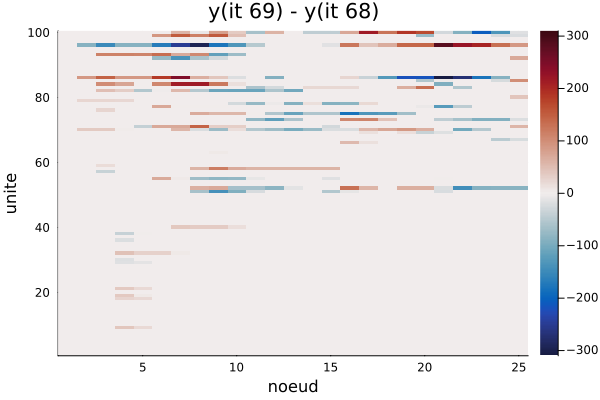

In [10]:
ITERATION = K-1    # iteration a examiner, comparee a la precedente
PASSE = 1        # passe avant de cette iteration (PASSES_PER_MIP passes par iteration)

actuel, avant = par_unite(ITERATION), par_unite(max(ITERATION - 1, 1))
texte(v) = isempty(v) ? "eteinte" : join(["[$a, $b]" for (a, b) in v], " ")

println("Intervalles de l'iteration $ITERATION ; * : unites qui different de l'iteration $(ITERATION - 1)\n")
for i in 1:instance.N
    isempty(actuel[i]) && isempty(avant[i]) && continue
    if actuel[i] == avant[i]
        println("   unite ", lpad(i, 3), " : ", texte(actuel[i]))
    else
        println(" * unite ", lpad(i, 3), " : ", texte(avant[i]), "  ->  ", texte(actuel[i]))
    end
end

y, y_avant = production(ITERATION, PASSE), production(max(ITERATION - 1, 1), PASSE)
zeta = reduce(hcat, states[ITERATION][PASSE].sampled_states_zeta)    # composantes de zeta x noeuds
dy = y .- y_avant

println("\nEtats echantillonnes de l'iteration $ITERATION (passe $PASSE) ; zeta (composantes x noeuds) :")
display(round.(zeta; digits = 4))
println("\nUnites dont la production y differe d'au moins 1e-6 de celle de l'iteration $(ITERATION - 1) :")
for i in findall(i -> maximum(abs, dy[i, :]) > 1e-6, 1:instance.N)
    n = argmax(abs.(dy[i, :]))
    @printf("   unite %3d : ecart max %8.3f au noeud %2d  (y = %.3f contre %.3f)\n", i, abs(dy[i, n]), n, y[i, n], y_avant[i, n])
end

m = max(maximum(abs, dy), 1e-9)
heatmap(dy; xlabel = "noeud", ylabel = "unite", color = :balance, clims = (-m, m),
        title = "y(it $ITERATION) - y(it $(ITERATION - 1))")

Unites dont y^k differe de y(gamma^k, ytilde^{k-1}) d'au moins 1e-6 (iteration 69, passe 1)
(l'intervalle est dit nouveau s'il n'etait pas choisi a l'iteration 68) :

   unite   2 : ecart max   62.650 au noeud  4  (y = 99.650 contre 37.000 ; intervalle deja choisi)
   unite   6 : ecart max   35.442 au noeud  4  (y = 90.556 contre 55.115 ; intervalle deja choisi)
   unite   7 : ecart max   27.582 au noeud  4  (y = 123.000 contre 95.418 ; intervalle deja choisi)
   unite   8 : ecart max   39.911 au noeud  4  (y = 85.089 contre 125.000 ; intervalle deja choisi)
   unite   9 : ecart max   46.822 au noeud  4  (y = 93.561 contre 46.740 ; intervalle deja choisi)
   unite  16 : ecart max   39.578 au noeud  4  (y = 120.000 contre 80.422 ; intervalle deja choisi)
   unite  18 : ecart max   48.275 au noeud  4  (y = 97.275 contre 49.000 ; intervalle deja choisi)
   unite  20 : ecart max   29.207 au noeud  4  (y = 111.000 contre 81.793 ; intervalle deja choisi)
   unite  21 : ecart max   69.160 au 

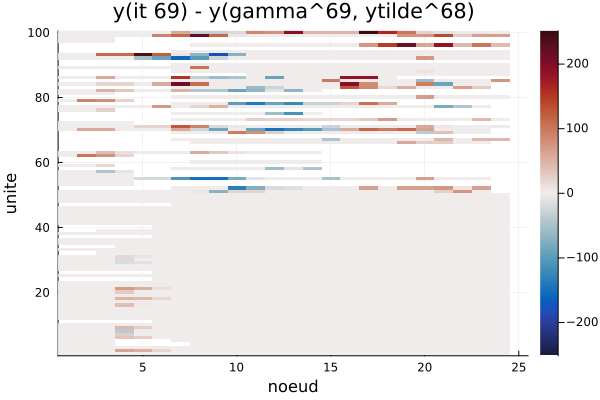

In [11]:
# y^k contre y(gamma^k, ytilde^{k-1}) a l'iteration ITERATION (definie dans la cellule precedente)
if METHOD != :extended || ITERATION < 2
    println("comparaison disponible en formulation intervalle, a partir de l'iteration 2")
else
    reel = production(ITERATION, PASSE)
    attendu, nouveau = y_gamma(ITERATION)
    ecart = reel .- attendu

    println("Unites dont y^k differe de y(gamma^k, ytilde^{k-1}) d'au moins 1e-6 (iteration $ITERATION, passe $PASSE)")
    println("(l'intervalle est dit nouveau s'il n'etait pas choisi a l'iteration $(ITERATION - 1)) :\n")
    for i in 1:instance.N
        valides = findall(!isnan, ecart[i, :])
        isempty(valides) && continue
        n = valides[argmax(abs.(ecart[i, valides]))]
        abs(ecart[i, n]) > 1e-6 || continue
        @printf("   unite %3d : ecart max %8.3f au noeud %2d  (y = %.3f contre %.3f ; intervalle %s)\n",
                i, abs(ecart[i, n]), n, reel[i, n], attendu[i, n], nouveau[i, n] ? "nouveau" : "deja choisi")
    end
    @printf("\n%d couples (unite, noeud) compares, dont %d avec un intervalle nouveau ; ecart max = %.3f\n",
            count(!isnan, ecart), count(nouveau), max_abs(ecart))

    m = max(max_abs(ecart), 1e-9)
    heatmap(ecart; xlabel = "noeud", ylabel = "unite", color = :balance, clims = (-m, m),
            title = "y(it $ITERATION) - y(gamma^$ITERATION, ytilde^$(ITERATION - 1))")
end

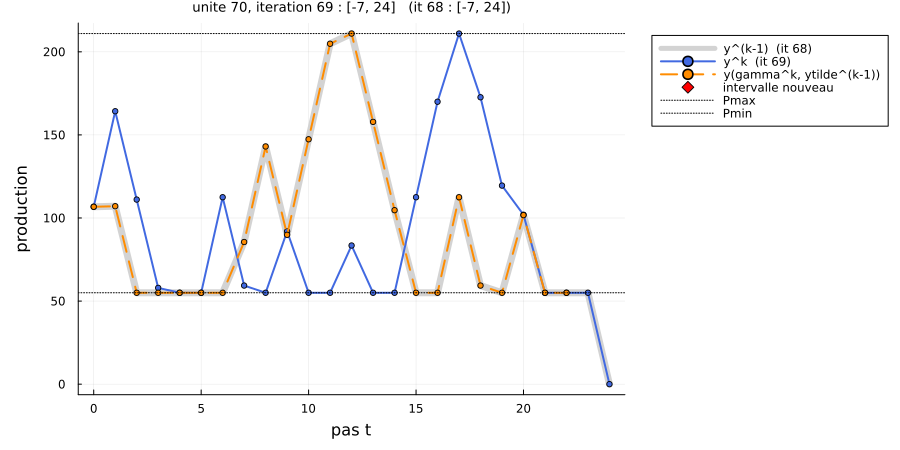

In [12]:
UNITE =  70   # unite a tracer ; l'iteration et la passe sont ITERATION et PASSE de la cellule de detail

# Trajectoires de la production de l'unite : y^k (iteration k), y^{k-1} (iteration k-1, derniere passe : celle dont
# les coupes sont les plus recentes) et y(gamma^k, ytilde^{k-1}). Losanges rouges : l'intervalle n'etait pas choisi
# a l'iteration k-1, ytilde est la trajectoire de cout minimal de la passe avant ; les trous de la courbe orange sont les pas ou la coupe ne
# depend pas de y_t. Le pas t est celui du noeud n = t+1.
let
    unit, k = instance.Thermalunits[UNITE], ITERATION
    avant = max(k - 1, 1)
    y_k = production(k, PASSE)[UNITE, :]
    y_avant = production(avant, length(states[avant]))[UNITE, :]
    attendu, nouveau = METHOD == :extended && k >= 2 ? y_gamma(k) : (fill(NaN, instance.N, T + 1), falses(instance.N, T + 1))
    decrit(v) = isempty(v) ? "eteinte" : join(["[$a, $b]" for (a, b) in v], " ")

    p = plot(0:T, y_avant; label = "y^(k-1)  (it $avant)", color = :lightgray, linewidth = 7,
             xlabel = "pas t", ylabel = "production", legend = :outertopright, titlefontsize = 9, size = (900, 450),
             left_margin = 6Plots.mm, bottom_margin = 5Plots.mm,
             title = "unite $UNITE, iteration $k : $(decrit(par_unite(k)[UNITE]))   (it $avant : $(decrit(par_unite(avant)[UNITE])))")
    plot!(p, 0:T, y_k; label = "y^k  (it $k)", color = :royalblue, linewidth = 2, marker = :circle, markersize = 3)
    plot!(p, 0:T, attendu[UNITE, :]; label = "y(gamma^k, ytilde^(k-1))", color = :darkorange,
          linewidth = 2, linestyle = :dash, marker = :circle, markersize = 3)
    scatter!(p, 0:T, [nouveau[UNITE, n] ? attendu[UNITE, n] : NaN for n in 1:T+1];
             label = "intervalle nouveau", color = :red, marker = :diamond, markersize = 6)
    hline!(p, [unit.MaxPower]; label = "Pmax", color = :black, linestyle = :dot)
    hline!(p, [unit.MinPower]; label = "Pmin", color = :black, linestyle = :dot)
    p
end


[-7, 24]  choisi it 68 et it 69 : ytilde = y^(k-1) (intervalle choisi)
  pas   z^F it 68   signe   ytilde_(t-1)         lo         hi    ytilde_t   y^(k-1)_t   |   z^F it 69   signe       y^k_t
    1    7.11e-15      ~0         106.76      55.00     164.24      107.08      107.08   |        -621   monte      164.24
    2         7.6 descend         107.08      55.00     164.57       55.00       55.00   |        16.6 descend      111.09
    3        19.4 descend          55.00      55.00     112.49       55.00       55.00   |        18.6 descend       57.94
    4        9.64 descend          55.00      55.00     112.49       55.00       55.00   |        8.56 descend       55.00
    5        7.67 descend          55.00      55.00     112.49       55.00       55.00   |        5.77 descend       55.00
    6       0.717 descend          55.00      55.00     112.49       55.00       55.00   |        -2.4   monte      112.49
    7    7.11e-15      ~0          55.00      55.00     112.49     

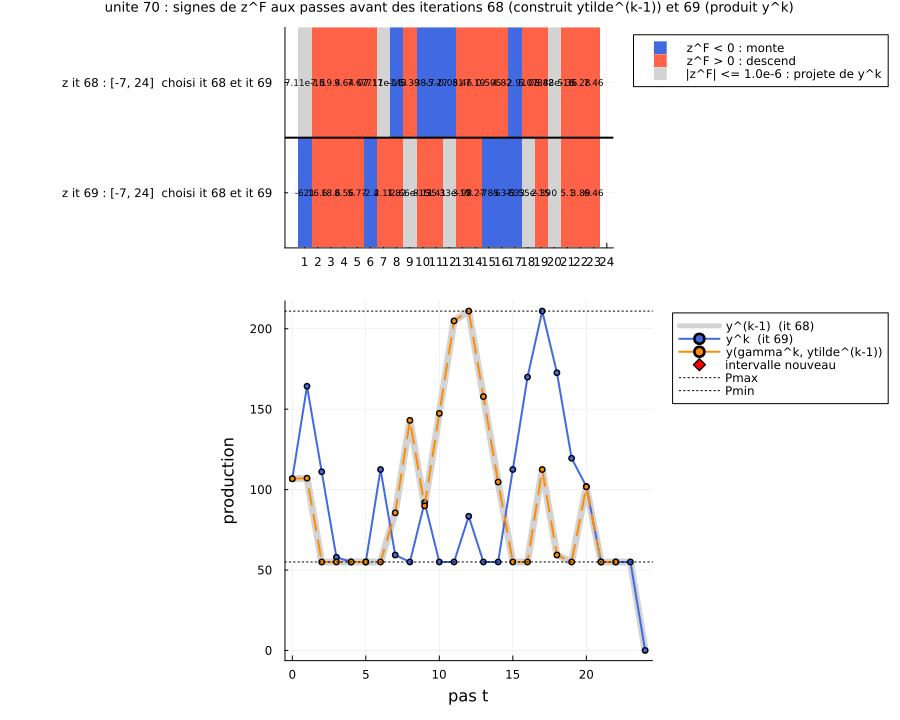

In [13]:
# Signaux de cout z^F de la passe avant pour l'unite UNITE (UNITE, ITERATION, PASSE : cellules precedentes). z^F_{j,a,b,t} (eq. (55)) est le cout
# marginal de produire au pas t (c_j - nu_t + pente de la valeur future de l'intervalle) ; il est calcule pour tous les intervalles actifs, choisis
# ou non. Deux passes : celle de l'iteration k-1 (derniere passe), qui construit ytilde^{k-1}, donc la courbe orange de la cellule precedente ;
# et celle de l'iteration k (PASSE), qui produit y^k avec la coupe de l'iteration k-1 : elle dit si la regle avait raison. Intervalles : ceux de
# l'unite choisis a l'iteration k-1 (y^{k-1} les suit : ytilde = y^{k-1}), puis ceux choisis seulement a l'iteration k (ytilde^{k-1} construit par
# la regle : losanges rouges de la courbe orange). Un intervalle choisi aux deux iterations est dans le premier groupe.
# Haut : une ligne par (passe, intervalle), signe de z^F, une case par pas ou l'intervalle est actif, avec la valeur de z^F. Bleu : z^F < 0, un
# intervalle non choisi y monte a fond. Rouge : z^F > 0, il y descend a fond. Gris : |z^F| <= TOL_Z, intervalle indifferent (typiquement l'unite
# marginale) : ytilde est la production y^{k-1} de l'unite projetee sur les successeurs de ytilde_{t-1}. Bas : les deux courbes de la cellule
# precedente, aux memes pas. Texte : par intervalle, z^F de la passe k-1, les bornes lo/hi des successeurs de ytilde_{t-1} et le ytilde_t obtenu,
# a comparer a y^{k-1}_t ; puis z^F de la passe k et la production y^k_t. Le pas t est celui de la production y_t (noeud n = t+1).
TOL_Z = MSUC.SIGNAL_TOLERANCE     # |z^F| <= TOL_Z : considere nul (meme seuil que la regle de la passe avant)
let
    k = ITERATION
    if METHOD != :extended || k < 2
        println("disponible en formulation intervalle, a partir de l'iteration 2")
    else
        unit, I = instance.Thermalunits[UNITE], instance.intervals
        yt = states[k-1][end].sampled_states_interval           # yt[n][id] : noeud n = pas t+1 (yt[1] : etat initial)
        Z = Dict(k - 1 => states[k-1][end].sampled_signals_interval,   # derniere passe de l'iteration k-1 : construit ytilde^{k-1}
                 k => states[k][PASSE].sampled_signals_interval)       # passe de l'iteration k : produit y^k ; Z[p][n][id]
        avant = [id for id in sort(schedules[k-1].selected) if I.unit[id] == UNITE]                          # y^{k-1} les suit
        seul_k = [id for id in sort(schedules[k].selected) if I.unit[id] == UNITE && !(id in avant)]         # ytilde^{k-1} par la regle
        ids = vcat(avant, seul_k)
        if isempty(ids)
            println("unite $UNITE : aucun intervalle choisi a l'iteration $k ni a l'iteration $(k-1)")
        else
            pas = 1:T
            signe(v) = isnan(v) ? NaN : abs(v) <= TOL_Z ? 0.0 : sign(v)
            lignes = [(p, id) for p in (k - 1, k) for id in ids]                    # (passe, intervalle) ; 1 ligne chacun
            classes = [signe(Z[p][t+1][id]) for (p, id) in lignes, t in pas]        # NaN : intervalle inactif
            role(id) = id in avant ? (id in schedules[k].selected ? "choisi it $(k-1) et it $k" : "choisi it $(k-1)") : "choisi it $k seulement"
            etiquettes = ["z it $p : [$(I.a[id]), $(I.b[id])]  " * role(id) for (p, id) in lignes]
            y_avant = production(k - 1, length(states[k-1]))[UNITE, :]
            y_k = production(k, PASSE)[UNITE, :]

            p1 = heatmap(pas, 1:length(lignes), classes; color = cgrad([:royalblue, :lightgray, :tomato]), clims = (-1, 1), colorbar = false,
                         yflip = true, yticks = (1:length(lignes), etiquettes), xticks = pas, xlims = (-0.5, T + 0.5), ylims = (0.5, length(lignes) + 0.5),
                         legend = :outertopright, titlefontsize = 9, title = "unite $UNITE : signes de z^F aux passes avant des iterations $(k-1) (construit ytilde^(k-1)) et $k (produit y^k)")
            annotate!(p1, [(t, r, text(@sprintf("%.3g", Z[p][t+1][id]), 6, :black)) for (r, (p, id)) in enumerate(lignes) for t in pas if !isnan(Z[p][t+1][id])])
            hline!(p1, [length(ids) + 0.5]; color = :black, linewidth = 2, label = "")          # separe la passe k-1 de la passe k
            for (couleur, nom) in ((:royalblue, "z^F < 0 : monte"), (:tomato, "z^F > 0 : descend"), (:lightgray, "|z^F| <= $TOL_Z : projete de y^k"))
                scatter!(p1, [NaN], [NaN]; color = couleur, marker = :square, markersize = 6, markerstrokewidth = 0, label = nom)
            end

            sens(v) = abs(v) <= TOL_Z ? "~0" : v < 0 ? "monte" : "descend"
            for id in ids
                a, b = I.a[id], I.b[id]
                println("\n[$a, $b]  ", role(id), id in avant ? " : ytilde = y^(k-1) (intervalle choisi)" : " : ytilde construit par la regle (intervalle non choisi a l'iteration $(k-1))")
                println("  pas   z^F it $(k-1)   signe   ytilde_(t-1)         lo         hi    ytilde_t   y^(k-1)_t   |   z^F it $k   signe       y^k_t")
                for t in pas
                    isnan(Z[k-1][t+1][id]) && continue
                    prec = yt[t][id]
                    lo = max(MSUC.p_lower(unit, a, b, t), prec - unit.DeltaRampDown)
                    hi = min(MSUC.p_upper(unit, a, b, t, T), prec + MSUC.ramp_up(unit, a, b, t))
                    zk = Z[k][t+1][id]
                    @printf("%5d %11.3g %7s %14.2f %10.2f %10.2f %11.2f %11.2f   | %11.3g %7s %11.2f\n", t, Z[k-1][t+1][id], sens(Z[k-1][t+1][id]),
                            prec, lo, hi, yt[t+1][id], y_avant[t+1], zk, isnan(zk) ? "-" : sens(zk), y_k[t+1])
                end
            end

            attendu, nouveau = y_gamma(k)
            p2 = plot(0:T, y_avant; label = "y^(k-1)  (it $(k-1))", color = :lightgray, linewidth = 7, xlims = (-0.5, T + 0.5),
                      xlabel = "pas t", ylabel = "production", legend = :outertopright)
            plot!(p2, 0:T, y_k; label = "y^k  (it $k)", color = :royalblue, linewidth = 2, marker = :circle, markersize = 3)
            plot!(p2, 0:T, attendu[UNITE, :]; label = "y(gamma^k, ytilde^(k-1))", color = :darkorange,
                  linewidth = 2, linestyle = :dash, marker = :circle, markersize = 3)
            scatter!(p2, 0:T, [nouveau[UNITE, n] ? attendu[UNITE, n] : NaN for n in 1:T+1];
                     label = "intervalle nouveau", color = :red, marker = :diamond, markersize = 6)
            hline!(p2, [unit.MaxPower]; label = "Pmax", color = :black, linestyle = :dot)
            hline!(p2, [unit.MinPower]; label = "Pmin", color = :black, linestyle = :dot)
            plot(p1, p2; layout = @layout([a{0.38h}; b]), size = (900, 720), left_margin = 14Plots.mm, bottom_margin = 3Plots.mm)
        end
    end
end

iteration 69, passe 1 : coupe de l'iteration 68 (position 1021). Ecart entre la somme des contributions et la
difference des valeurs de la coupe, au pire noeud : 1.83e-09

noeud  variation de la coupe   dont positive   dont negative
    2                 -9.6             0.0            -9.6
    3                454.7          1317.5          -862.9
    4              -3413.2             0.0         -3413.2
    5              -1556.6            17.7         -1574.3
    6               -255.6             0.0          -255.6
    7              -3602.3             0.1         -3602.4
    8             -27322.9          9598.8        -36921.7
    9              10764.6         33071.6        -22307.0
   10              -1279.3             0.1         -1279.4
   11               1346.2          3918.7         -2572.5
   12              -3482.0          2003.1         -5485.1
   13              -2901.6             0.0         -2901.6
   14               -772.6            91.7          -864.3


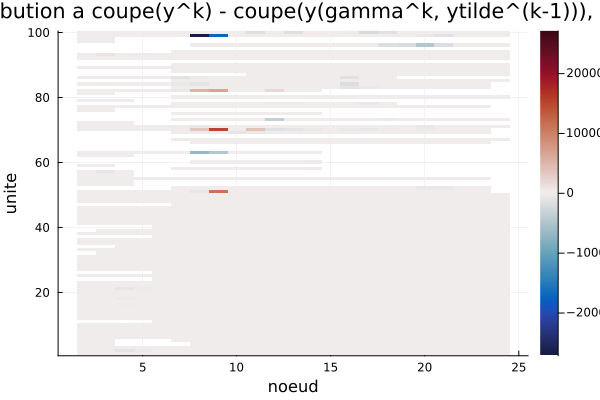

In [14]:
# Contribution de chaque unite a la variation de la valeur de la coupe de l'iteration k-1 quand l'etat visite y^k
# s'ecarte du point y(gamma^k, ytilde^{k-1}) ou elle a ete linearisee. La coupe est affine en y :
#     coupe(gamma, y) = alpha + delta.zeta + somme, sur les intervalles choisis, de (tau_id + beta_id y_unite),
# donc coupe(y^k) - coupe(y(gamma^k, ytilde^{k-1})) = somme_j beta_j (y^k_j - ytilde_j), et chaque terme est la
# contribution de l'unite j. Positive : la coupe est plus haute (futur plus cher) au point visite qu'au point de
# linearisation ; negative : plus basse. Signe de la pente beta_j : < 0, produire plus aujourd'hui fait baisser le
# cout futur (la montee en puissance est valorisee) ; = 0, branche limitee par la capacite ; > 0, produire coute.
# Le noeud n est l'etat y_t avec t = n-1 ; seuls les noeuds 2 a T portent une coupe d'etape.
if METHOD != :extended || ITERATION < 2
    println("disponible en formulation intervalle, a partir de l'iteration 2")
else
    k, unit = ITERATION, instance.Thermalunits[UNITE]
    I = instance.intervals
    reel = production(k, PASSE)
    attendu, nouveau = y_gamma(k)
    # coupe de la derniere passe de l'iteration k-1 : position 1 = coupe triviale, puis PASSES_PER_MIP par iteration
    position = 1 + (k - 1) * PASSES_PER_MIP

    # intervalle de gamma^k actif au noeud n (pas t+1 = n) pour chaque unite
    ident = zeros(Int, instance.N, T + 1)
    for id in schedules[k].selected, n in 1:T
        MSUC.is_on_interval(I.a[id], I.b[id], n) && (ident[I.unit[id], n] = id)
    end

    pente = fill(NaN, instance.N, T + 1)     # beta_j de la coupe
    contribution = fill(NaN, instance.N, T + 1)
    erreurs = Float64[]
    for n in 2:T
        cut = model[n].cuts[position]
        for i in 1:instance.N
            ident[i, n] == 0 && continue
            pente[i, n] = cut.beta[ident[i, n]]
            contribution[i, n] = pente[i, n] * (reel[i, n] - attendu[i, n])
        end
        # verification : somme des contributions = coupe(y^k) - coupe(y(gamma^k, ytilde^{k-1}))
        zeta = states[k][PASSE].sampled_states_zeta[n]
        valeur(y) = cut.alpha + sum(cut.delta .* zeta) +
                    sum(cut.beta[id] * y[I.unit[id]] + cut.tau[id] for id in schedules[k].selected)
        y_tilde = ifelse.(isnan.(attendu[:, n]), reel[:, n], attendu[:, n])
        push!(erreurs, abs(valeur(reel[:, n]) - valeur(y_tilde) - sum(filter(!isnan, contribution[:, n]); init = 0.0)))
    end
    @printf("iteration %d, passe %d : coupe de l'iteration %d (position %d). Ecart entre la somme des contributions et la\n", k, PASSE, k - 1, position)
    @printf("difference des valeurs de la coupe, au pire noeud : %.2e\n\n", maximum(erreurs))

    # par noeud : variation totale de la valeur de la coupe, et ses parts positive et negative
    println("noeud  variation de la coupe   dont positive   dont negative")
    for n in 2:T
        c = filter(!isnan, contribution[:, n])
        @printf("%5d %20.1f %15.1f %15.1f\n", n, sum(c; init = 0.0), sum(x -> max(x, 0.0), c; init = 0.0), sum(x -> min(x, 0.0), c; init = 0.0))
    end

    # par unite, sur tous les noeuds : les unites qui pesent le plus
    totaux = [sum(filter(!isnan, contribution[i, :]); init = 0.0) for i in 1:instance.N]
    absolus = [sum(abs, filter(!isnan, contribution[i, :]); init = 0.0) for i in 1:instance.N]
    println("\nunites qui contribuent le plus (somme sur les noeuds, et somme des valeurs absolues) :")
    for i in sortperm(absolus; rev = true)[1:min(10, instance.N)]
        @printf("   unite %3d : somme = %12.1f   somme des |.| = %12.1f\n", i, totaux[i], absolus[i])
    end

    # detail de l'unite UNITE
    println("\nunite $UNITE : Pmin = $(unit.MinPower), Pmax = $(unit.MaxPower), montee max R_up = $(unit.DeltaRampUp), descente max R_dn = $(unit.DeltaRampDown), cout lineaire = $(unit.LinearTerm)")
    println("noeud   y^k    y~^(k-1)   ecart    pente beta   contribution   montee y^k    intervalle")
    for n in 2:T
        id = ident[UNITE, n]
        id == 0 && continue
        @printf("%5d %7.1f %9.1f %8.1f %12.3f %13.1f %12.1f    [%d, %d] %s\n", n, reel[UNITE, n], attendu[UNITE, n], reel[UNITE, n] - attendu[UNITE, n],
                pente[UNITE, n], contribution[UNITE, n], reel[UNITE, n] - reel[UNITE, n-1], I.a[id], I.b[id], nouveau[UNITE, n] ? "(nouveau)" : "")
    end

    m = max(maximum(abs, filter(!isnan, contribution); init = 0.0), 1e-9)
    heatmap(contribution; xlabel = "noeud", ylabel = "unite", color = :balance, clims = (-m, m),
            title = "contribution a coupe(y^k) - coupe(y(gamma^k, ytilde^(k-1))), it $k")
end

### Temps de calcul par poste

Chronometres de `train` : racine (MIP), passe avant, passe arriere (resolution des LP, calcul des
coefficients des coupes, ajout des coupes) et mise a jour du planning.

In [17]:
MSUC.TimerOutputs.print_timer(stdout, model.timer_output; compact = true)

─────────────────────────────────────────────────────────────────────
                                          Time          Allocations  
                                    ───────────────   ───────────────
          Total measured:                 699s            49.5GiB    

Section                     ncalls     time    %tot     alloc    %tot
─────────────────────────────────────────────────────────────────────
solve_first_stage_problem       70     390s   69.3%    309MiB    0.7%
backward_pass                1.05k     125s   22.2%   27.6GiB   60.9%
  solve_subproblem            121k    96.8s   17.2%   8.38GiB   18.5%
    get_dual_solution         121k    1.91s    0.3%    668MiB    1.4%
  compute_coefficients       24.2k    23.1s    4.1%   18.2GiB   40.2%
  add_cut                    24.2k    5.04s    0.9%   0.96GiB    2.1%
forward_pass                 1.05k    40.2s    7.1%   14.1GiB   31.1%
  solve_subproblem           25.2k    30.9s    5.5%   1.85GiB    4.1%
    get_dual_soluti

### Temps du MIP racine par iteration

Le probleme racine est un MIP resolu a chaque iteration : c'est en general le poste dominant de `train`.
Son temps croit avec le nombre de coupes accumulees ; l'option `MIP_GAP` (cellule des parametres) permet de l'accelerer.

MIP racine : 388.9 s au total, soit 69 % du temps d'entrainement (563.8 s)


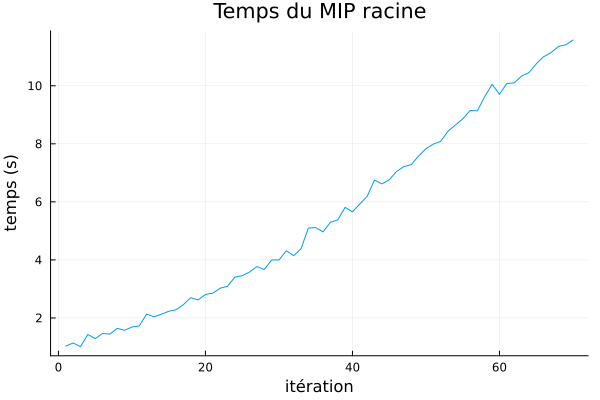

In [16]:
using Plots
t_mip = model[1].computation_time[1:length(log)]   # une resolution du MIP racine par iteration
@printf("MIP racine : %.1f s au total, soit %.0f %% du temps d'entrainement (%.1f s)\n",
        sum(t_mip), 100 * sum(t_mip) / log[end].time, log[end].time)
plot(t_mip, title = "Temps du MIP racine", xlabel = "itération", ylabel = "temps (s)", legend = false)